# Auckland Climate Analysis, 1966–2026

**Business question:** How has Auckland's climate changed over the last 60 years, and what should city
planners, energy providers and businesses expect now?

**Second question:** Can a simple model predict tomorrow's weather well enough to be useful?

## Executive summary

1. **Auckland has warmed by about 1.1 °C since 1966** (+0.18 °C per decade, p < 0.001).
2. **Hot days (≥ 25 °C) have more than tripled**, from 3.8 a year in the 1960s to 13.5 a year in the 2020s.
   The extra heat is concentrated in January and February.
3. **Cold nights (≤ 5 °C) have fallen by two thirds**, from 13.8 to 4.7 a year.
4. **Rainfall shows no clear long-term trend.** Year-to-year swings are much larger than any change.
5. **My original forecast model was no better than guessing.** Tested on unseen years, it matched
   "always predict no rain" exactly. Adding today's weather fixed this, but the gain over a simple
   "tomorrow = today" rule is small.

**Recommendations** are at the end of the notebook.

## 1. Data

- **Source:** [Open-Meteo](https://open-meteo.com/) historical weather API, ERA5 reanalysis, for Auckland (−36.94, 174.78).
- **Coverage:** one row per day, 1 January 1966 to 20 October 2026 (22,208 days).
- **Columns:** daily max / min / mean temperature (°C) and total rainfall (mm).
- **What ERA5 is:** a reconstruction of past weather that combines weather stations, satellites and weather
  balloons into a consistent grid. It has no gaps, which makes it good for long-term trends, but each grid
  cell covers tens of kilometres, so it smooths out very local events. This matters later.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, accuracy_score

plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#999999", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "font.size": 10,
})
ACCENT, MUTED = "#2a6fdb", "#b8c4d6"

# The Open-Meteo CSV export starts with 2 metadata lines and a blank line.
df = pd.read_csv("auckland_daily_era5.csv", skiprows=3)
df.columns = ["date", "max_temp", "min_temp", "mean_temp", "rainfall"]
df["date"] = pd.to_datetime(df["date"])
df.head()

,date,max_temp,min_temp,mean_temp,rainfall
0,1966-01-01,22.4,17.6,19.6,0.0
1,1966-01-02,24.1,17.1,20.7,6.0
2,1966-01-03,22.5,18.9,20.3,1.7
3,1966-01-04,22.8,18.9,20.3,0.6
4,1966-01-05,22.3,18.5,20.0,0.1


## 2. Data quality checks

Before any analysis I check for missing values, gaps in the calendar, impossible values and incomplete years.
The same checks are in [`sql/02_data_quality.sql`](../sql/02_data_quality.sql).

In [2]:
checks = {
    "rows": len(df),
    "first day": df.date.min().date(),
    "last day": df.date.max().date(),
    "missing values": int(df.isna().sum().sum()),
    "duplicate dates": int(df.date.duplicated().sum()),
    "calendar gaps": int((df.date.diff().dt.days > 1).sum()),
    "min > max": int((df.min_temp > df.max_temp).sum()),
    "mean outside min-max": int(((df.mean_temp < df.min_temp) | (df.mean_temp > df.max_temp)).sum()),
    "negative rain": int((df.rainfall < 0).sum()),
}
pd.Series(checks, name="result").to_frame()

,result
rows,22208
first day,1966-01-01
last day,2026-10-20
missing values,0
duplicate dates,0
calendar gaps,0
min > max,0
mean outside min-max,0
negative rain,0


In [3]:
df["year"] = df.date.dt.year
days_per_year = df.groupby("year").size()
incomplete = days_per_year[days_per_year < 360]
print("Incomplete years (excluded from yearly totals):", incomplete.to_dict())

full = df[df.year.isin(days_per_year[days_per_year >= 360].index)]

Incomplete years (excluded from yearly totals): {2026: 293}


**Result:** the data is clean. No missing values, gaps or impossible values. The only issue is that **2026 is
incomplete** (data ends in October), so it is excluded from anything summed or averaged by year. Otherwise
2026 would look unusually dry simply because its summer and spring are missing.

Definitions used below:
- **Hot day:** maximum temperature ≥ 25 °C
- **Cold night:** minimum temperature ≤ 5 °C
- **Rainy day:** more than 1 mm of rain

In [4]:
yearly = full.groupby("year").agg(
    mean_temp=("mean_temp", "mean"),
    hot_days=("max_temp", lambda s: (s >= 25).sum()),
    cold_nights=("min_temp", lambda s: (s <= 5).sum()),
    rainfall=("rainfall", "sum"),
)
yearly["decade"] = yearly.index // 10 * 10

def trend(col):
    fit = stats.linregress(yearly.index, yearly[col])
    return pd.Series({"change per decade": round(fit.slope * 10, 2), "p-value": round(fit.pvalue, 4)})

pd.DataFrame({c: trend(c) for c in ["mean_temp", "hot_days", "cold_nights", "rainfall"]}).T

,change per decade,p-value
mean_temp,0.18,0.0000
hot_days,1.16,0.0122
cold_nights,-1.22,0.0005
rainfall,-3.42,0.7970


## 3. Finding 1: Auckland has warmed by about 1.1 °C

A straight-line trend through the yearly averages rises by **0.18 °C per decade**, and the p-value is far below
0.05, so this is very unlikely to be chance. Four of the five warmest years have happened since 2016.

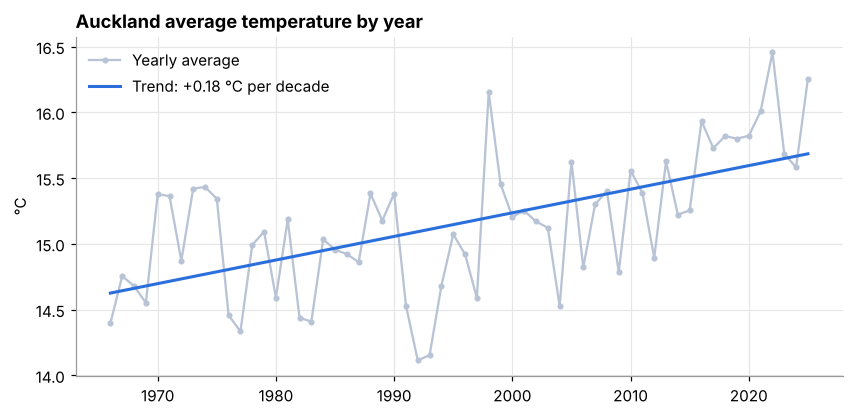

Warmest years:


year
2022    16.46
2025    16.26
1998    16.15
2021    16.01
2016    15.93
Name: mean_temp, dtype: float64

In [5]:
fit = stats.linregress(yearly.index, yearly.mean_temp)
fig, ax = plt.subplots()
ax.plot(yearly.index, yearly.mean_temp, color=MUTED, lw=1.5, marker="o", ms=3, label="Yearly average")
ax.plot(yearly.index, fit.intercept + fit.slope * yearly.index, color=ACCENT, lw=2,
        label=f"Trend: +{fit.slope*10:.2f} °C per decade")
ax.set_title("Auckland average temperature by year")
ax.set_ylabel("°C"); ax.legend(frameon=False, loc="upper left")
plt.show()

print("Warmest years:")
yearly.mean_temp.sort_values(ascending=False).head(5).round(2)

## 4. Finding 2: hot days have more than tripled

A 1 °C change in the average sounds small. The number of hot days shows what it means in practice.

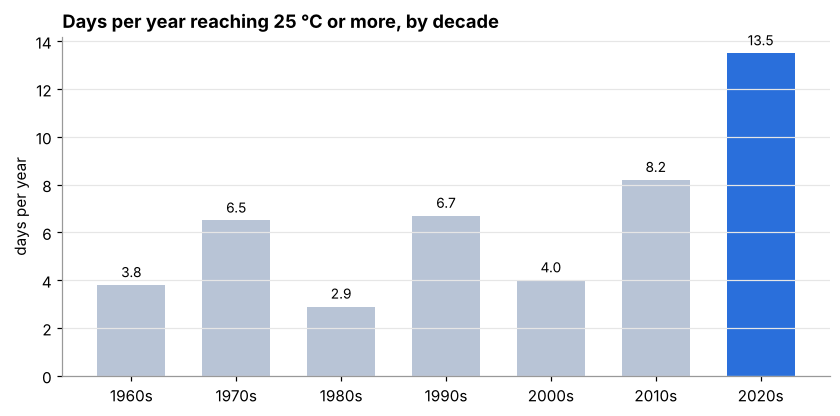

,years,hot_days,cold_nights,rainfall
1960s,4,3.8,13.8,1241.0
1970s,10,6.5,9.6,1247.0
1980s,10,2.9,8.9,1155.3
1990s,10,6.7,6.5,1111.8
2000s,10,4.0,7.7,1113.6
2010s,10,8.2,5.3,1078.7
2020s,6,13.5,4.7,1377.8


In [6]:
decades = yearly.groupby("decade").agg(
    years=("mean_temp", "size"), hot_days=("hot_days", "mean"),
    cold_nights=("cold_nights", "mean"), rainfall=("rainfall", "mean"),
).round(1)
decades.index = [f"{d}s" for d in decades.index]

fig, ax = plt.subplots()
colors = [MUTED] * (len(decades) - 1) + [ACCENT]
bars = ax.bar(decades.index, decades.hot_days, color=colors, width=0.65)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)
ax.set_title("Days per year reaching 25 °C or more, by decade")
ax.set_ylabel("days per year"); ax.grid(axis="x", visible=False)
plt.show()

decades

Note: the 1960s include 4 years (1966–69) and the 2020s include 6 complete years (2020–25).

**Which months are getting hotter?** Comparing the first 20 years with the most recent 20:

In [7]:
df["month"] = df.date.dt.month
early = df[df.year.between(1966, 1985)]
recent = df[df.year.between(2006, 2025)]
by_month = pd.DataFrame({
    "1966–1985": early[early.max_temp >= 25].groupby("month").size() / 20,
    "2006–2025": recent[recent.max_temp >= 25].groupby("month").size() / 20,
}).fillna(0).round(1)
by_month.index = [pd.Timestamp(2000, m, 1).strftime("%b") for m in by_month.index]
by_month

,1966–1985,2006–2025
Jan,1.8,3.7
Feb,2.7,4.0
Mar,0.4,1.0
Nov,0.0,0.1
Dec,0.0,0.8


Almost all of the extra hot days fall in **December to March**. January hot days have doubled and February's are up by half.
Summers are getting hotter, rather than the hot season getting longer.

## 5. Finding 3: rainfall has not clearly changed

Annual rainfall has no statistically significant trend (p = 0.80). Some recent years have been very wet,
but wet and dry years have always alternated.

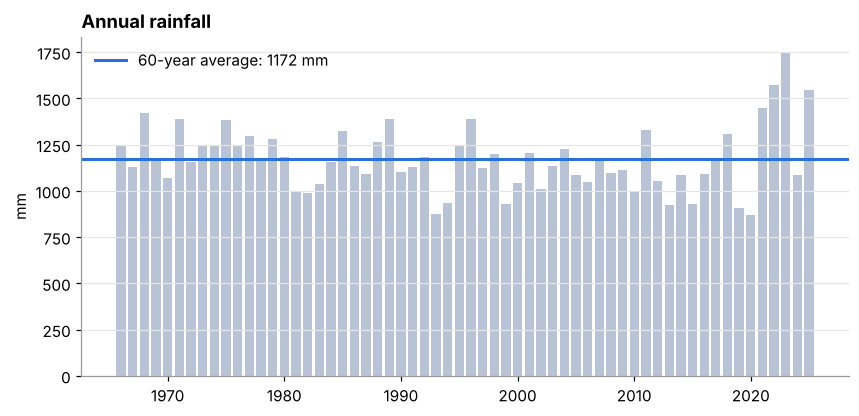

Wettest single days:


,date,rainfall
0,2011-01-29,124.6
1,2025-07-29,101.6
2,1969-02-16,96.1
3,1972-03-08,90.7
4,2011-01-23,89.7
5,2023-02-13,88.1
6,2023-01-27,83.4
7,1967-02-02,82.0


In [8]:
fig, ax = plt.subplots()
ax.bar(yearly.index, yearly.rainfall, color=MUTED, width=0.8)
ax.axhline(yearly.rainfall.mean(), color=ACCENT, lw=2, label=f"60-year average: {yearly.rainfall.mean():.0f} mm")
ax.set_title("Annual rainfall"); ax.set_ylabel("mm"); ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.show()

print("Wettest single days:")
df.nlargest(8, "rainfall")[["date", "rainfall"]].reset_index(drop=True)

**Data limitation:** the 27 January 2023 Auckland Anniversary flood, a record-breaking rain event, only ranks **#7** in this dataset. Because ERA5 averages over a large grid cell, it spreads
out intense local downpours. This data is reliable for long-term temperature trends, but should **not** be
used to judge extreme rainfall or flood risk.

## 6. Can a simple model predict tomorrow's weather?

My original model predicted the weather from the day of the year alone, and reported R² = 0.76 and 66% rain
accuracy. Those numbers were measured on the same data the model was trained on, with nothing to compare against.

Here I test it properly:
- **Train** on 1966–2015, **test** on 2016–2026 (years the model never saw).
- **Compare** with simple baselines that need no model at all.

In [9]:
d = df.copy()
d["rainy"] = (d.rainfall > 1).astype(int)
d["next_max"] = d.max_temp.shift(-1)
d["next_rainy"] = d.rainy.shift(-1)
d = d.dropna(subset=["next_max", "next_rainy"])
d["next_doy"] = (d.date + pd.Timedelta(days=1)).dt.dayofyear

def season(doy):
    x = 2 * np.pi * np.asarray(doy) / 365.25
    return np.column_stack([np.sin(x), np.cos(x), np.sin(2 * x), np.cos(2 * x)])

X_season = season(d.next_doy)
X_full = np.column_stack([X_season, d.max_temp, d.min_temp, d.max_temp - d.min_temp,
                          d.rainy, np.log1p(d.rainfall)])
train, test = (d.year < 2016).values, (d.year >= 2016).values
y_t, y_r = d.next_max.values, d.next_rainy.astype(int).values

temp = {
    "Original: season only": LinearRegression().fit(X_season[train], y_t[train]).predict(X_season[test]),
    "Baseline: same as today": d.max_temp.values[test],
    "Improved: season + today": LinearRegression().fit(X_full[train], y_t[train]).predict(X_full[test]),
}
rain = {
    "Baseline: always 'no rain'": np.zeros(test.sum()),
    "Original: season only": LogisticRegression(max_iter=1000).fit(X_season[train], y_r[train]).predict(X_season[test]),
    "Baseline: same as today": d.rainy.values[test],
    "Improved: season + today": LogisticRegression(max_iter=1000).fit(X_full[train], y_r[train]).predict(X_full[test]),
}

temp_results = pd.Series({k: mean_absolute_error(y_t[test], v) for k, v in temp.items()},
                         name="Average error (°C)").round(2).to_frame()
rain_results = pd.Series({k: accuracy_score(y_r[test], v) for k, v in rain.items()},
                         name="Accuracy").map("{:.1%}".format).to_frame()
print(f"Test days: {test.sum():,}   Rain on {y_r[test].mean():.0%} of them\n")
print("TOMORROW'S HIGH TEMPERATURE (lower is better)"); print(temp_results.to_string(), "\n")
print("WILL IT RAIN TOMORROW? (higher is better)");      print(rain_results.to_string())

Test days: 3,945   Rain on 40% of them

TOMORROW'S HIGH TEMPERATURE (lower is better)
                          Average error (°C)
Original: season only                   1.47
Baseline: same as today                 1.06
Improved: season + today                1.00 

WILL IT RAIN TOMORROW? (higher is better)
                           Accuracy
Baseline: always 'no rain'    59.8%
Original: season only         59.8%
Baseline: same as today       66.6%
Improved: season + today      68.3%


**What this shows:**
- The original **rain model scores exactly the same as always guessing "no rain"**. It learned nothing beyond
  the fact that most days are dry.
- The original **temperature model is beaten by "tomorrow = today"**.
- Adding today's weather gives the best result on both tasks, but only slightly better than the simple baseline.
  Predicting tomorrow's weather properly needs forecast inputs such as air pressure and wind, not just history.

**Lesson:** a model is only useful if it beats a simple baseline, and it must be tested on data it has not seen.

## 7. Recommendations

1. **Plan for hot summers as the new normal.** Planning that assumes around 5 hot days a year (the 20th-century
   average) is out of date. The 2020s average is 13.5, mostly in January and February. This is relevant to
   cooling in schools, rest homes and rental housing, and to summer staffing and outdoor work.
2. **Businesses with summer-sensitive demand** (cold drinks, ice cream, fans, outdoor venues, electricity
   retailers) should plan stock and capacity around January–February, where hot days are now far more common.
3. **Do not use this dataset for flood planning.** Rainfall shows no clear trend here, but gridded data
   smooths out extreme downpours, as the 2023 flood shows. Flood decisions need local rain-gauge data.
4. **For day-ahead decisions, use a real weather forecast.** Simple history-based models add little over
   "tomorrow will be like today".

## 8. Limitations and next steps

- ERA5 is a reanalysis grid, not a single weather station. Long-term temperature trends agree well with
  station records, but local extremes are underestimated.
- Trends are simple straight lines. Climate cycles such as El Niño and La Niña cause year-to-year swings
  that are not modelled here.
- 2026 is excluded from yearly figures because the year is incomplete.
- **Next steps:** compare with NIWA station data for Auckland Airport, and add El Niño / La Niña phases to
  explain the year-to-year variation.